In [333]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn import datasets, preprocessing
from sklearn import svm
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn import datasets
from scipy.cluster.hierarchy import ward, dendrogram, linkage
from yellowbrick.cluster import KElbowVisualizer 
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import ward, fcluster
import seaborn as sns
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.metrics import silhouette_score
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

In [334]:
#read data and import data to notebook with pandas library
data = "ionosphere.data" 
ionosphere_df = pd.read_csv(data, delim_whitespace=False, header=None)

# Create a new row with our attributes names  
col_name = ['A01', 'A02', 'A03', 'A04','A05','A06','A07', 'A08','A09','A10','A11', 'A12', 'A13', 'A14','A15','A16','A17', 'A18','A19','A20','A21', 'A22', 'A23', 'A24','A25','A26','A27', 'A28','A29','A30','A31', 'A32', 'A33', 'A34','Class']
ionosphere_df.columns = col_name

#Verify that the data is loaded correctly by plotting the dataset
ionosphere_df

,A01,A02,A03,A04,A05,A06,A07,A08,A09,A10,...,A26,A27,A28,A29,A30,A31,A32,A33,A34,Class
0,1,0,0.99539,-0.05889,0.85243,0.02306,0.83398,-0.37708,1.00000,0.03760,...,-0.51171,0.41078,-0.46168,0.21266,-0.34090,0.42267,-0.54487,0.18641,-0.45300,g
1,1,0,1.00000,-0.18829,0.93035,-0.36156,-0.10868,-0.93597,1.00000,-0.04549,...,-0.26569,-0.20468,-0.18401,-0.19040,-0.11593,-0.16626,-0.06288,-0.13738,-0.02447,b
2,1,0,1.00000,-0.03365,1.00000,0.00485,1.00000,-0.12062,0.88965,0.01198,...,-0.40220,0.58984,-0.22145,0.43100,-0.17365,0.60436,-0.24180,0.56045,-0.38238,g
3,1,0,1.00000,-0.45161,1.00000,1.00000,0.71216,-1.00000,0.00000,0.00000,...,0.90695,0.51613,1.00000,1.00000,-0.20099,0.25682,1.00000,-0.32382,1.00000,b
4,1,0,1.00000,-0.02401,0.94140,0.06531,0.92106,-0.23255,0.77152,-0.16399,...,-0.65158,0.13290,-0.53206,0.02431,-0.62197,-0.05707,-0.59573,-0.04608,-0.65697,g
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
346,1,0,0.83508,0.08298,0.73739,-0.14706,0.84349,-0.05567,0.90441,-0.04622,...,-0.04202,0.83479,0.00123,1.00000,0.12815,0.86660,-0.10714,0.90546,-0.04307,g
347,1,0,0.95113,0.00419,0.95183,-0.02723,0.93438,-0.01920,0.94590,0.01606,...,0.01361,0.93522,0.04925,0.93159,0.08168,0.94066,-0.00035,0.91483,0.04712,g
348,1,0,0.94701,-0.00034,0.93207,-0.03227,0.95177,-0.03431,0.95584,0.02446,...,0.03193,0.92489,0.02542,0.92120,0.02242,0.92459,0.00442,0.92697,-0.00577,g
349,1,0,0.90608,-0.01657,0.98122,-0.01989,0.95691,-0.03646,0.85746,0.00110,...,-0.02099,0.89147,-0.07760,0.82983,-0.17238,0.96022,-0.03757,0.87403,-0.16243,g


By checking the above plotted data as well as the information about the ionosphere dataset we can see that we do not have any missing values. We have the exact given number of instances (351) and the same number of attributes (34 plus the class attribute = 35 total attributes). Furthermore, another method to check if we any missing values to our data is by using the isna() method (Missing values are denoted with NaN: Not a Number). 
The isna() method returns a DataFrame object where all the NaN (missing) values are replaced with a Boolean value True and otherwise False.

In [335]:
#isna method to find any missing values
ionosphere_df.isna()

,A01,A02,A03,A04,A05,A06,A07,A08,A09,A10,...,A26,A27,A28,A29,A30,A31,A32,A33,A34,Class
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
346,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
347,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
348,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
349,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In the case of having missing (Not a number) values, we would get to the above table boolean value True. Since we do not have any True values appearing we can say thet we do not have missing values to our data. Veryfying that, if we want to count how many missing values there are, we can sum the result of isna(), since in the sum True values become 1 and False become 0. 

In [336]:
#counting the missing values
ionosphere_df.isna().sum()

A01      0
A02      0
A03      0
A04      0
A05      0
A06      0
A07      0
A08      0
A09      0
A10      0
A11      0
A12      0
A13      0
A14      0
A15      0
A16      0
A17      0
A18      0
A19      0
A20      0
A21      0
A22      0
A23      0
A24      0
A25      0
A26      0
A27      0
A28      0
A29      0
A30      0
A31      0
A32      0
A33      0
A34      0
Class    0
dtype: int64

Moving to the next step, the class (category) of the pattern in embedded in the data (our column 35 "Class") so we are going to create a separate table that stores these values. 

In [337]:
#creating a table that includes only the class data (good  or bad)
class_category = ionosphere_df.loc[:,'Class']
class_category

0      g
1      b
2      g
3      b
4      g
      ..
346    g
347    g
348    g
349    g
350    g
Name: Class, Length: 351, dtype: object

There is no unnecessary information that we can say that's being included in our data features.

In [338]:
#Our new table without the class data is the one below

new_table = ionosphere_df.loc[:,['A01','A02', 'A03', 'A04','A05','A06','A07', 'A08','A09','A10','A11', 'A12', 'A13', 'A14','A15','A16','A17', 'A18','A19','A20','A21', 'A22', 'A23', 'A24','A25','A26','A27', 'A28','A29','A30','A31', 'A32', 'A33', 'A34']]
new_table

,A01,A02,A03,A04,A05,A06,A07,A08,A09,A10,...,A25,A26,A27,A28,A29,A30,A31,A32,A33,A34
0,1,0,0.99539,-0.05889,0.85243,0.02306,0.83398,-0.37708,1.00000,0.03760,...,0.56811,-0.51171,0.41078,-0.46168,0.21266,-0.34090,0.42267,-0.54487,0.18641,-0.45300
1,1,0,1.00000,-0.18829,0.93035,-0.36156,-0.10868,-0.93597,1.00000,-0.04549,...,-0.20332,-0.26569,-0.20468,-0.18401,-0.19040,-0.11593,-0.16626,-0.06288,-0.13738,-0.02447
2,1,0,1.00000,-0.03365,1.00000,0.00485,1.00000,-0.12062,0.88965,0.01198,...,0.57528,-0.40220,0.58984,-0.22145,0.43100,-0.17365,0.60436,-0.24180,0.56045,-0.38238
3,1,0,1.00000,-0.45161,1.00000,1.00000,0.71216,-1.00000,0.00000,0.00000,...,1.00000,0.90695,0.51613,1.00000,1.00000,-0.20099,0.25682,1.00000,-0.32382,1.00000
4,1,0,1.00000,-0.02401,0.94140,0.06531,0.92106,-0.23255,0.77152,-0.16399,...,0.03286,-0.65158,0.13290,-0.53206,0.02431,-0.62197,-0.05707,-0.59573,-0.04608,-0.65697
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
346,1,0,0.83508,0.08298,0.73739,-0.14706,0.84349,-0.05567,0.90441,-0.04622,...,0.95378,-0.04202,0.83479,0.00123,1.00000,0.12815,0.86660,-0.10714,0.90546,-0.04307
347,1,0,0.95113,0.00419,0.95183,-0.02723,0.93438,-0.01920,0.94590,0.01606,...,0.94520,0.01361,0.93522,0.04925,0.93159,0.08168,0.94066,-0.00035,0.91483,0.04712
348,1,0,0.94701,-0.00034,0.93207,-0.03227,0.95177,-0.03431,0.95584,0.02446,...,0.93988,0.03193,0.92489,0.02542,0.92120,0.02242,0.92459,0.00442,0.92697,-0.00577
349,1,0,0.90608,-0.01657,0.98122,-0.01989,0.95691,-0.03646,0.85746,0.00110,...,0.91050,-0.02099,0.89147,-0.07760,0.82983,-0.17238,0.96022,-0.03757,0.87403,-0.16243


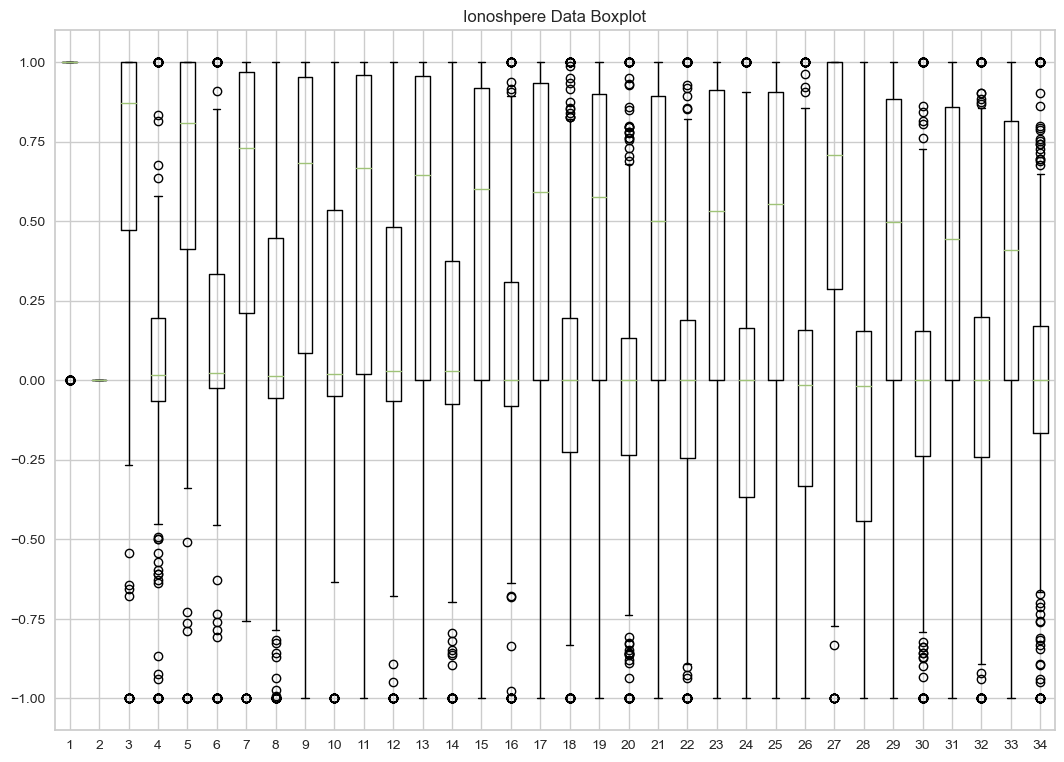

In [339]:
#boxplots to derive our dataset

fig = plt.figure(figsize =(10, 7))
 
# Creating axes instance
axis1 = fig.add_axes([0, 0, 1, 1])

axis1.set_title('Ionoshpere Data Boxplot')
bp = axis1.boxplot(new_table)
#plt.grid(False) hiding the grid to have a better vision of the data

In order to remove the outliers from our boxplot we can simply just add the showfliers argument as False in the function call. So we get the below boxplot.

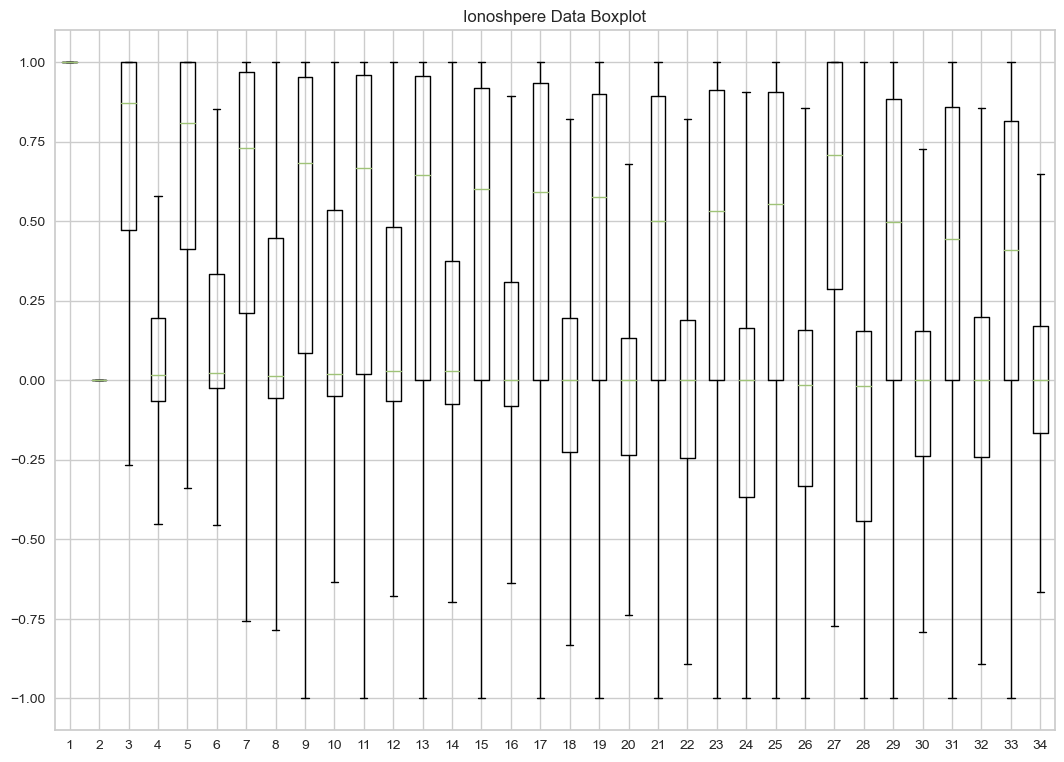

In [340]:

fig2 = plt.figure(figsize =(10, 7))
 
# Creating axes instance
axis2 = fig2.add_axes([0, 0, 1, 1])

axis2.set_title('Ionoshpere Data Boxplot')
no_outliers = axis2.boxplot(new_table, showfliers=False)

In [341]:
min_max_scaler = preprocessing.MinMaxScaler()
A=np.array(new_table)  #creating an array A of the given data
A_minmax = min_max_scaler.fit_transform(A)   #transforming data into [0,1] range

#normalizing the above array
A_normalized = pd.DataFrame(A_minmax)

#removing any letters from the dataset and replacing them with 0 and 1 
#zeros for g (good) and ones for b (bad)
class_category = class_category.replace({'g': 0, 'b': 1}) 


C:\Users\eleni\anaconda3\lib\site-packages\pandas\plotting\_matplotlib\misc.py:100: UserWarning: Attempting to set identical left == right == 0.0 results in singular transformations; automatically expanding.
  ax.set_xlim(boundaries_list[j])
C:\Users\eleni\anaconda3\lib\site-packages\pandas\plotting\_matplotlib\misc.py:101: UserWarning: Attempting to set identical bottom == top == 0.0 results in singular transformations; automatically expanding.
  ax.set_ylim(boundaries_list[i])
C:\Users\eleni\anaconda3\lib\site-packages\pandas\plotting\_matplotlib\misc.py:91: UserWarning: Attempting to set identical left == right == 0.0 results in singular transformations; automatically expanding.
  ax.set_xlim(boundaries_list[i])


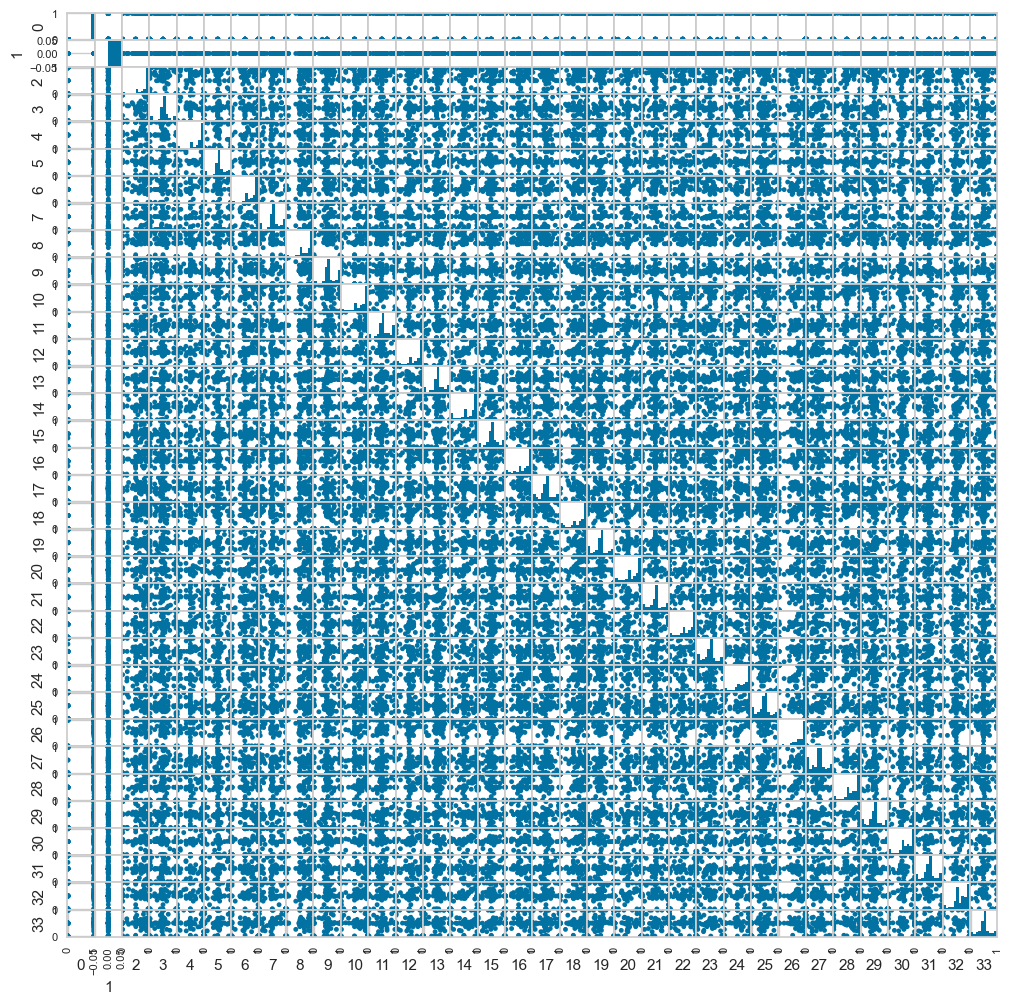

In [342]:
#visualizing all the instances in the dataset
pd.plotting.scatter_matrix(A_normalized,class_category, figsize=(12, 12))
plt.show()

In [343]:
# get the locations
X = A_normalized.iloc[:, :]
y = class_category.iloc[:]

#split the dataset into training and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0, train_size = .70) 

In [344]:
#printing the shapes of the training and test data
print(X_train.shape,y_train.shape)
print(X_test.shape, y_test.shape)

(245, 34) (245,)
(106, 34) (106,)


Plotting below the analytic training and test set of the data

In [345]:
X_train

,0,1,2,3,4,5,6,7,8,9,...,24,25,26,27,28,29,30,31,32,33
168,0.0,0.0,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,...,0.500000,0.500000,1.000000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000
316,1.0,0.0,0.947945,0.696430,0.830645,0.859020,0.647605,0.954120,0.476065,0.972075,...,0.607905,0.071485,0.766145,0.157035,0.874230,0.296720,0.915710,0.464855,0.884310,0.639630
142,1.0,0.0,1.000000,0.472355,1.000000,0.000000,0.750000,0.444445,0.680555,0.388890,...,1.000000,0.361110,1.000000,0.214540,1.000000,0.361110,1.000000,0.184220,1.000000,0.170325
81,0.0,0.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000
1,1.0,0.0,1.000000,0.405855,0.965175,0.319220,0.445660,0.032015,1.000000,0.477255,...,0.398340,0.367155,0.397660,0.407995,0.404800,0.442035,0.416870,0.468560,0.431310,0.487765
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
323,1.0,0.0,0.696970,0.378790,0.813275,0.506350,0.727275,0.545455,0.818180,0.545455,...,0.742630,0.529645,0.731810,0.530710,0.666665,0.484850,0.709280,0.532050,0.696970,0.621210
192,1.0,0.0,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,...,0.000000,0.750000,0.520835,0.875000,0.385415,0.000000,0.437500,0.364585,0.401040,0.031250
117,1.0,0.0,0.990910,0.500000,0.943135,0.515655,0.931245,0.522860,0.900000,0.500000,...,0.872725,0.613635,0.822905,0.575440,0.836365,0.513635,0.803575,0.582325,0.794200,0.585385
47,1.0,0.0,0.972990,0.486575,0.000000,0.630655,0.318035,0.678195,0.846290,0.182865,...,0.919360,0.266330,0.761040,0.209350,1.000000,0.193035,0.451830,0.602385,0.469415,0.709565


In [346]:
X_test

,0,1,2,3,4,5,6,7,8,9,...,24,25,26,27,28,29,30,31,32,33
6,1.0,0.0,0.987940,0.446990,0.973005,0.396000,0.964030,0.358250,0.929980,0.363290,...,0.613960,0.091830,0.568295,0.087450,0.523030,0.088025,0.478690,0.093410,0.430840,0.095125
52,1.0,0.0,1.000000,1.000000,1.000000,1.000000,0.955050,1.000000,0.365150,1.000000,...,0.950070,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.326570,1.000000,0.674225
114,1.0,0.0,0.956765,0.907930,0.135135,1.000000,0.302670,0.778675,0.527025,0.648650,...,0.499985,0.500010,0.499995,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000
45,0.0,0.0,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.500000,0.500000,0.500000
106,1.0,0.0,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,...,0.500000,0.500000,1.000000,0.554880,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
135,1.0,0.0,0.948530,0.691175,0.955880,0.687500,0.871325,0.838235,0.727940,0.889705,...,0.128675,0.437500,0.160375,0.379345,0.224265,0.286765,0.279410,0.246325,0.356620,0.216910
341,1.0,0.0,0.990010,0.500375,1.000000,0.500000,0.994910,0.499625,0.973605,0.511970,...,0.970775,0.540535,0.983545,0.536275,0.978505,0.540440,0.990950,0.540630,0.986235,0.543080
335,1.0,0.0,1.000000,0.493290,1.000000,0.507830,1.000000,0.498880,1.000000,0.531320,...,1.000000,0.550335,0.999945,0.543815,0.995525,0.542505,1.000000,0.550335,1.000000,0.550335
298,1.0,0.0,0.941205,0.653170,0.866160,0.789080,0.670545,0.792635,0.528585,1.000000,...,0.213790,0.161975,0.341950,0.090620,0.485105,0.065795,0.626960,0.089365,0.500970,0.091570


In [347]:
y_train 

168    1
316    0
142    1
81     1
1      1
      ..
323    0
192    1
117    0
47     1
172    1
Name: Class, Length: 245, dtype: int64

In [348]:
y_test

6      0
52     0
114    1
45     1
106    1
      ..
135    0
341    0
335    0
298    0
120    1
Name: Class, Length: 106, dtype: int64

Linear Discriminant Analysis (Linear Classifier)

In [349]:
clf = LinearDiscriminantAnalysis()
clf.fit(X_train, y_train)  #fitting the linear discriminant model to the training data

#Making predictions on the test data
y_pred = clf.predict(X_test)

#Generate a classification report for evaluation metrics
report = classification_report(y_test, y_pred)
print("Classification report for the Linear Discriminant Analysis:")
print(report)

Classification report for the Linear Discriminant Analysis:
              precision    recall  f1-score   support

           0       0.83      1.00      0.91        62
           1       1.00      0.70      0.83        44

    accuracy                           0.88       106
   macro avg       0.91      0.85      0.87       106
weighted avg       0.90      0.88      0.87       106



Quadratic Discriminant Analysis (Quadratic classifier)

In [350]:
clf_quadratic = QuadraticDiscriminantAnalysis()
clf_quadratic = QuadraticDiscriminantAnalysis().fit(X_train, y_train) #fitting the linear discriminant model to the training data

#Making predictions on the test data
y2_pred=clf_quadratic.predict(X_test)

#Generate a classification report for evaluation metrics
report2 = classification_report(y_test, y2_pred)
print("Classification report for the Quadratic Discriminant Analysis:")
print(report2)

Classification report for the Quadratic Discriminant Analysis:
              precision    recall  f1-score   support

           0       0.93      0.90      0.92        62
           1       0.87      0.91      0.89        44

    accuracy                           0.91       106
   macro avg       0.90      0.91      0.90       106
weighted avg       0.91      0.91      0.91       106



C:\Users\eleni\anaconda3\lib\site-packages\sklearn\discriminant_analysis.py:878: UserWarning: Variables are collinear
  warnings.warn("Variables are collinear")


In order to be able to compare the performance of each classifier we will try a few more ways of separating the data in the training and test data division. 

In [351]:
# train set size=0.80 , test size=0.20
X2_train, X2_test, y2_train, y2_test = train_test_split(X, y, random_state=0, train_size = .80) 

# train set size=0.90 , test size=0.10
X3_train, X3_test, y3_train, y3_test = train_test_split(X, y, random_state=0, train_size = .90) 


Applying the Linear and Quadratic Classifiers to the above training and test data

In [352]:
#for the training size=0.80 , test size=0.20
clf2 = LinearDiscriminantAnalysis()
clf2.fit(X2_train, y2_train)  #fitting the linear discriminant model to the training data

#Making predictions on the test data
y3_pred = clf2.predict(X2_test)

clf_quadratic2 = QuadraticDiscriminantAnalysis().fit(X2_train, y2_train) #fitting the linear discriminant model to the training data

#Making predictions on the test data
y4_pred=clf_quadratic2.predict(X2_test)

#Generate a classification report for evaluation metrics
report3 = classification_report(y2_test, y3_pred)
print("Classification report for the Linear Discriminant Analysis (test size=0.2):")
print(report3)

#Generate a classification report for evaluation metrics
report4 = classification_report(y2_test, y4_pred)
print("Classification report for the Quadratic Discriminant Analysis:")
print(report4)



Classification report for the Linear Discriminant Analysis (test size=0.2):
              precision    recall  f1-score   support

           0       0.84      1.00      0.91        41
           1       1.00      0.73      0.85        30

    accuracy                           0.89        71
   macro avg       0.92      0.87      0.88        71
weighted avg       0.91      0.89      0.88        71

Classification report for the Quadratic Discriminant Analysis:
              precision    recall  f1-score   support

           0       0.97      0.85      0.91        41
           1       0.83      0.97      0.89        30

    accuracy                           0.90        71
   macro avg       0.90      0.91      0.90        71
weighted avg       0.91      0.90      0.90        71



C:\Users\eleni\anaconda3\lib\site-packages\sklearn\discriminant_analysis.py:878: UserWarning: Variables are collinear
  warnings.warn("Variables are collinear")


In [353]:
#for the training size=0.90 , test size=0.10

clf3 = LinearDiscriminantAnalysis()
clf3.fit(X3_train, y3_train)  #fitting the linear discriminant model to the training data

#Making predictions on the test data
y5_pred = clf3.predict(X3_test)

clf_quadratic3 = QuadraticDiscriminantAnalysis().fit(X3_train, y3_train) #fitting the linear discriminant model to the training data

#Making predictions on the test data
y6_pred=clf_quadratic2.predict(X3_test)

#Generate a classification report for evaluation metrics
report5 = classification_report(y3_test, y5_pred)
print("Classification report for the Linear Discriminant Analysis (test size=0.2):")
print(report3)

#Generate a classification report for evaluation metrics
report6 = classification_report(y3_test, y6_pred)
print("Classification report for the Quadratic Discriminant Analysis:")
print(report6)

Classification report for the Linear Discriminant Analysis (test size=0.2):
              precision    recall  f1-score   support

           0       0.84      1.00      0.91        41
           1       1.00      0.73      0.85        30

    accuracy                           0.89        71
   macro avg       0.92      0.87      0.88        71
weighted avg       0.91      0.89      0.88        71

Classification report for the Quadratic Discriminant Analysis:
              precision    recall  f1-score   support

           0       0.94      0.77      0.85        22
           1       0.72      0.93      0.81        14

    accuracy                           0.83        36
   macro avg       0.83      0.85      0.83        36
weighted avg       0.86      0.83      0.84        36



C:\Users\eleni\anaconda3\lib\site-packages\sklearn\discriminant_analysis.py:878: UserWarning: Variables are collinear
  warnings.warn("Variables are collinear")


Elbow Method

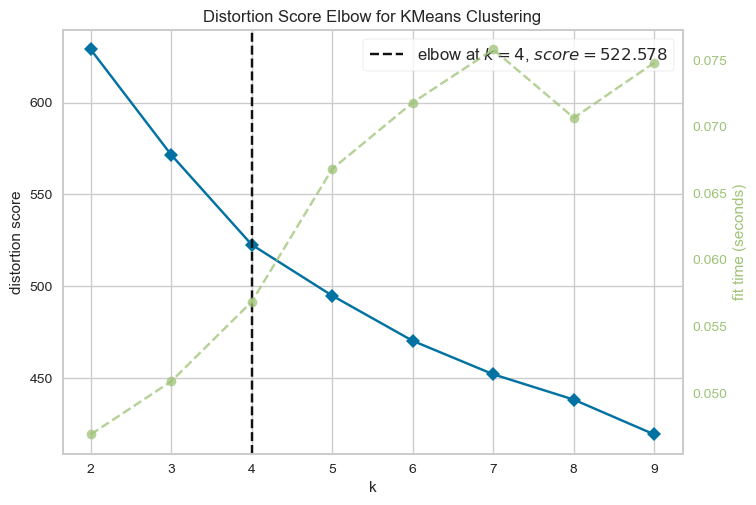

<AxesSubplot:title={'center':'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [354]:
#elbow method in order to estimate the number of clusters
#determines the optimal number of clusters in K-means clustering and plots the value of the cost function produced by different values of K

model = KMeans()
visualizer = KElbowVisualizer(model, k=(2,10), timings=True ,locate_elbow=True)
visualizer.fit(A_normalized) # Fit the data to the visualizer
visualizer.show()  # Finalize and render the figure

By deploying the elbow method we can see that the value of k is 4 meaning that we have four clusters. 

Silhouette Analysis 

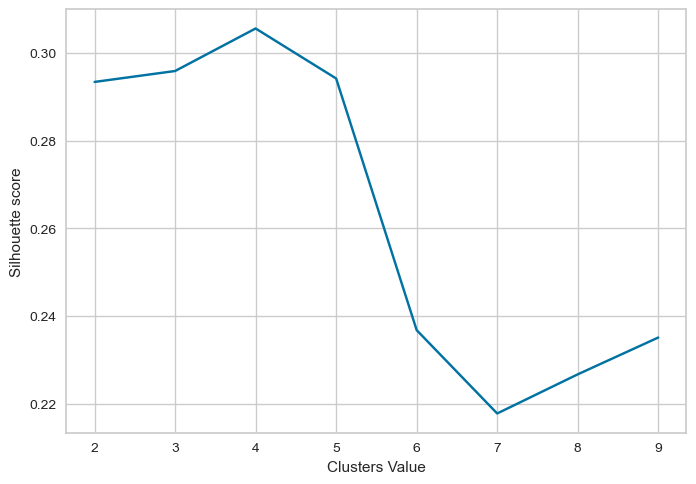

In [355]:
#deploying the Silhouette analysis in order to study the separation distance between the resulting clusters.
sse_ = []  #creating some space 

for k in range(2,10):
    kmeans = KMeans(n_clusters=k, random_state=0).fit(A_normalized)
    sil_coeff = silhouette_score(A_normalized, kmeans.labels_, metric='euclidean')
    sse_.append(sil_coeff) #Instruction in order to append the element to the end of the list


plt.ylabel('Silhouette score')
plt.xlabel('Clusters Value')
plt.plot(range(2,10), sse_)

In [356]:
#Deploying the k-means to the data

#Kmeans and kmeans visualization

kmeans = KMeans(n_clusters=4, random_state=0).fit(A_normalized) #deploying the kmeans and computing k-means clustering. number of clusters 4
y_kmeans = kmeans.predict(A_normalized)  #Predict the closest cluster each sample in the normalized array belongs to.

In [357]:
#finding the clusters centers
kmeans.cluster_centers_

array([[0.7228, 0.    , 0.5837, 0.4841, 0.5221, 0.5279, 0.534 , 0.5014,
        0.5923, 0.5401, 0.5944, 0.4858, 0.5211, 0.4517, 0.4734, 0.4867,
        0.5772, 0.4594, 0.5736, 0.4561, 0.4949, 0.4946, 0.5113, 0.4743,
        0.5532, 0.4749, 0.735 , 0.415 , 0.5156, 0.4608, 0.4783, 0.5194,
        0.5004, 0.5163],
       [0.9545, 0.    , 0.9155, 0.4823, 0.9357, 0.5088, 0.9212, 0.4799,
        0.912 , 0.4993, 0.9189, 0.514 , 0.9245, 0.4931, 0.9225, 0.489 ,
        0.9049, 0.4781, 0.8909, 0.4797, 0.8966, 0.5204, 0.8878, 0.4666,
        0.8707, 0.4722, 0.8876, 0.4858, 0.8554, 0.4849, 0.8539, 0.4859,
        0.8451, 0.4766],
       [1.    , 0.    , 0.8961, 0.7138, 0.8018, 0.7944, 0.6437, 0.9064,
        0.4541, 0.9289, 0.2773, 0.868 , 0.1788, 0.7446, 0.1131, 0.5963,
        0.1548, 0.395 , 0.2295, 0.2928, 0.3392, 0.1947, 0.4626, 0.2318,
        0.5944, 0.2301, 0.7026, 0.3163, 0.7225, 0.4277, 0.7035, 0.4759,
        0.6761, 0.5895],
       [0.9429, 0.    , 0.9438, 0.6193, 0.923 , 0.6284, 0.882

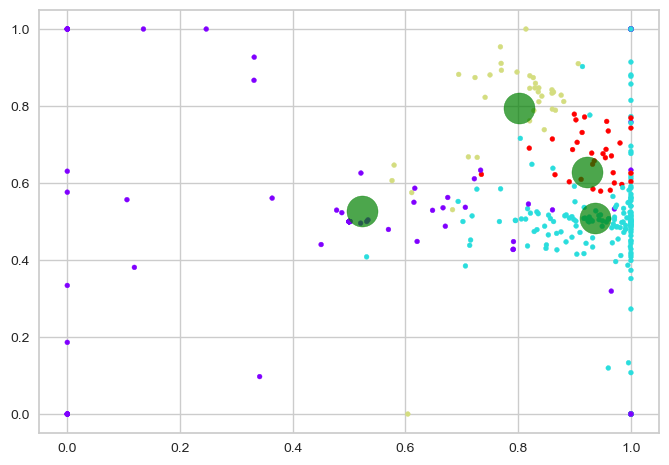

In [358]:
#plotting the scatter of data 
plt.scatter(A_normalized.iloc[:, 4], A_normalized.iloc[:, 5], c=y_kmeans, s=12, cmap='rainbow')
centers = kmeans.cluster_centers_  #defining the clusters' centers. Coordinates of cluster centers

#plotting the kmeans 
plt.scatter(centers[:,4], centers[:,5], c='green', s=500, alpha=0.7);

The above plot shows the scatered data as well as the four clusters (data range field 0-1)

In [359]:
#deploying the linkage with the ward method
np.set_printoptions(precision=4, suppress=True)
distance = linkage(A_normalized, 'ward')

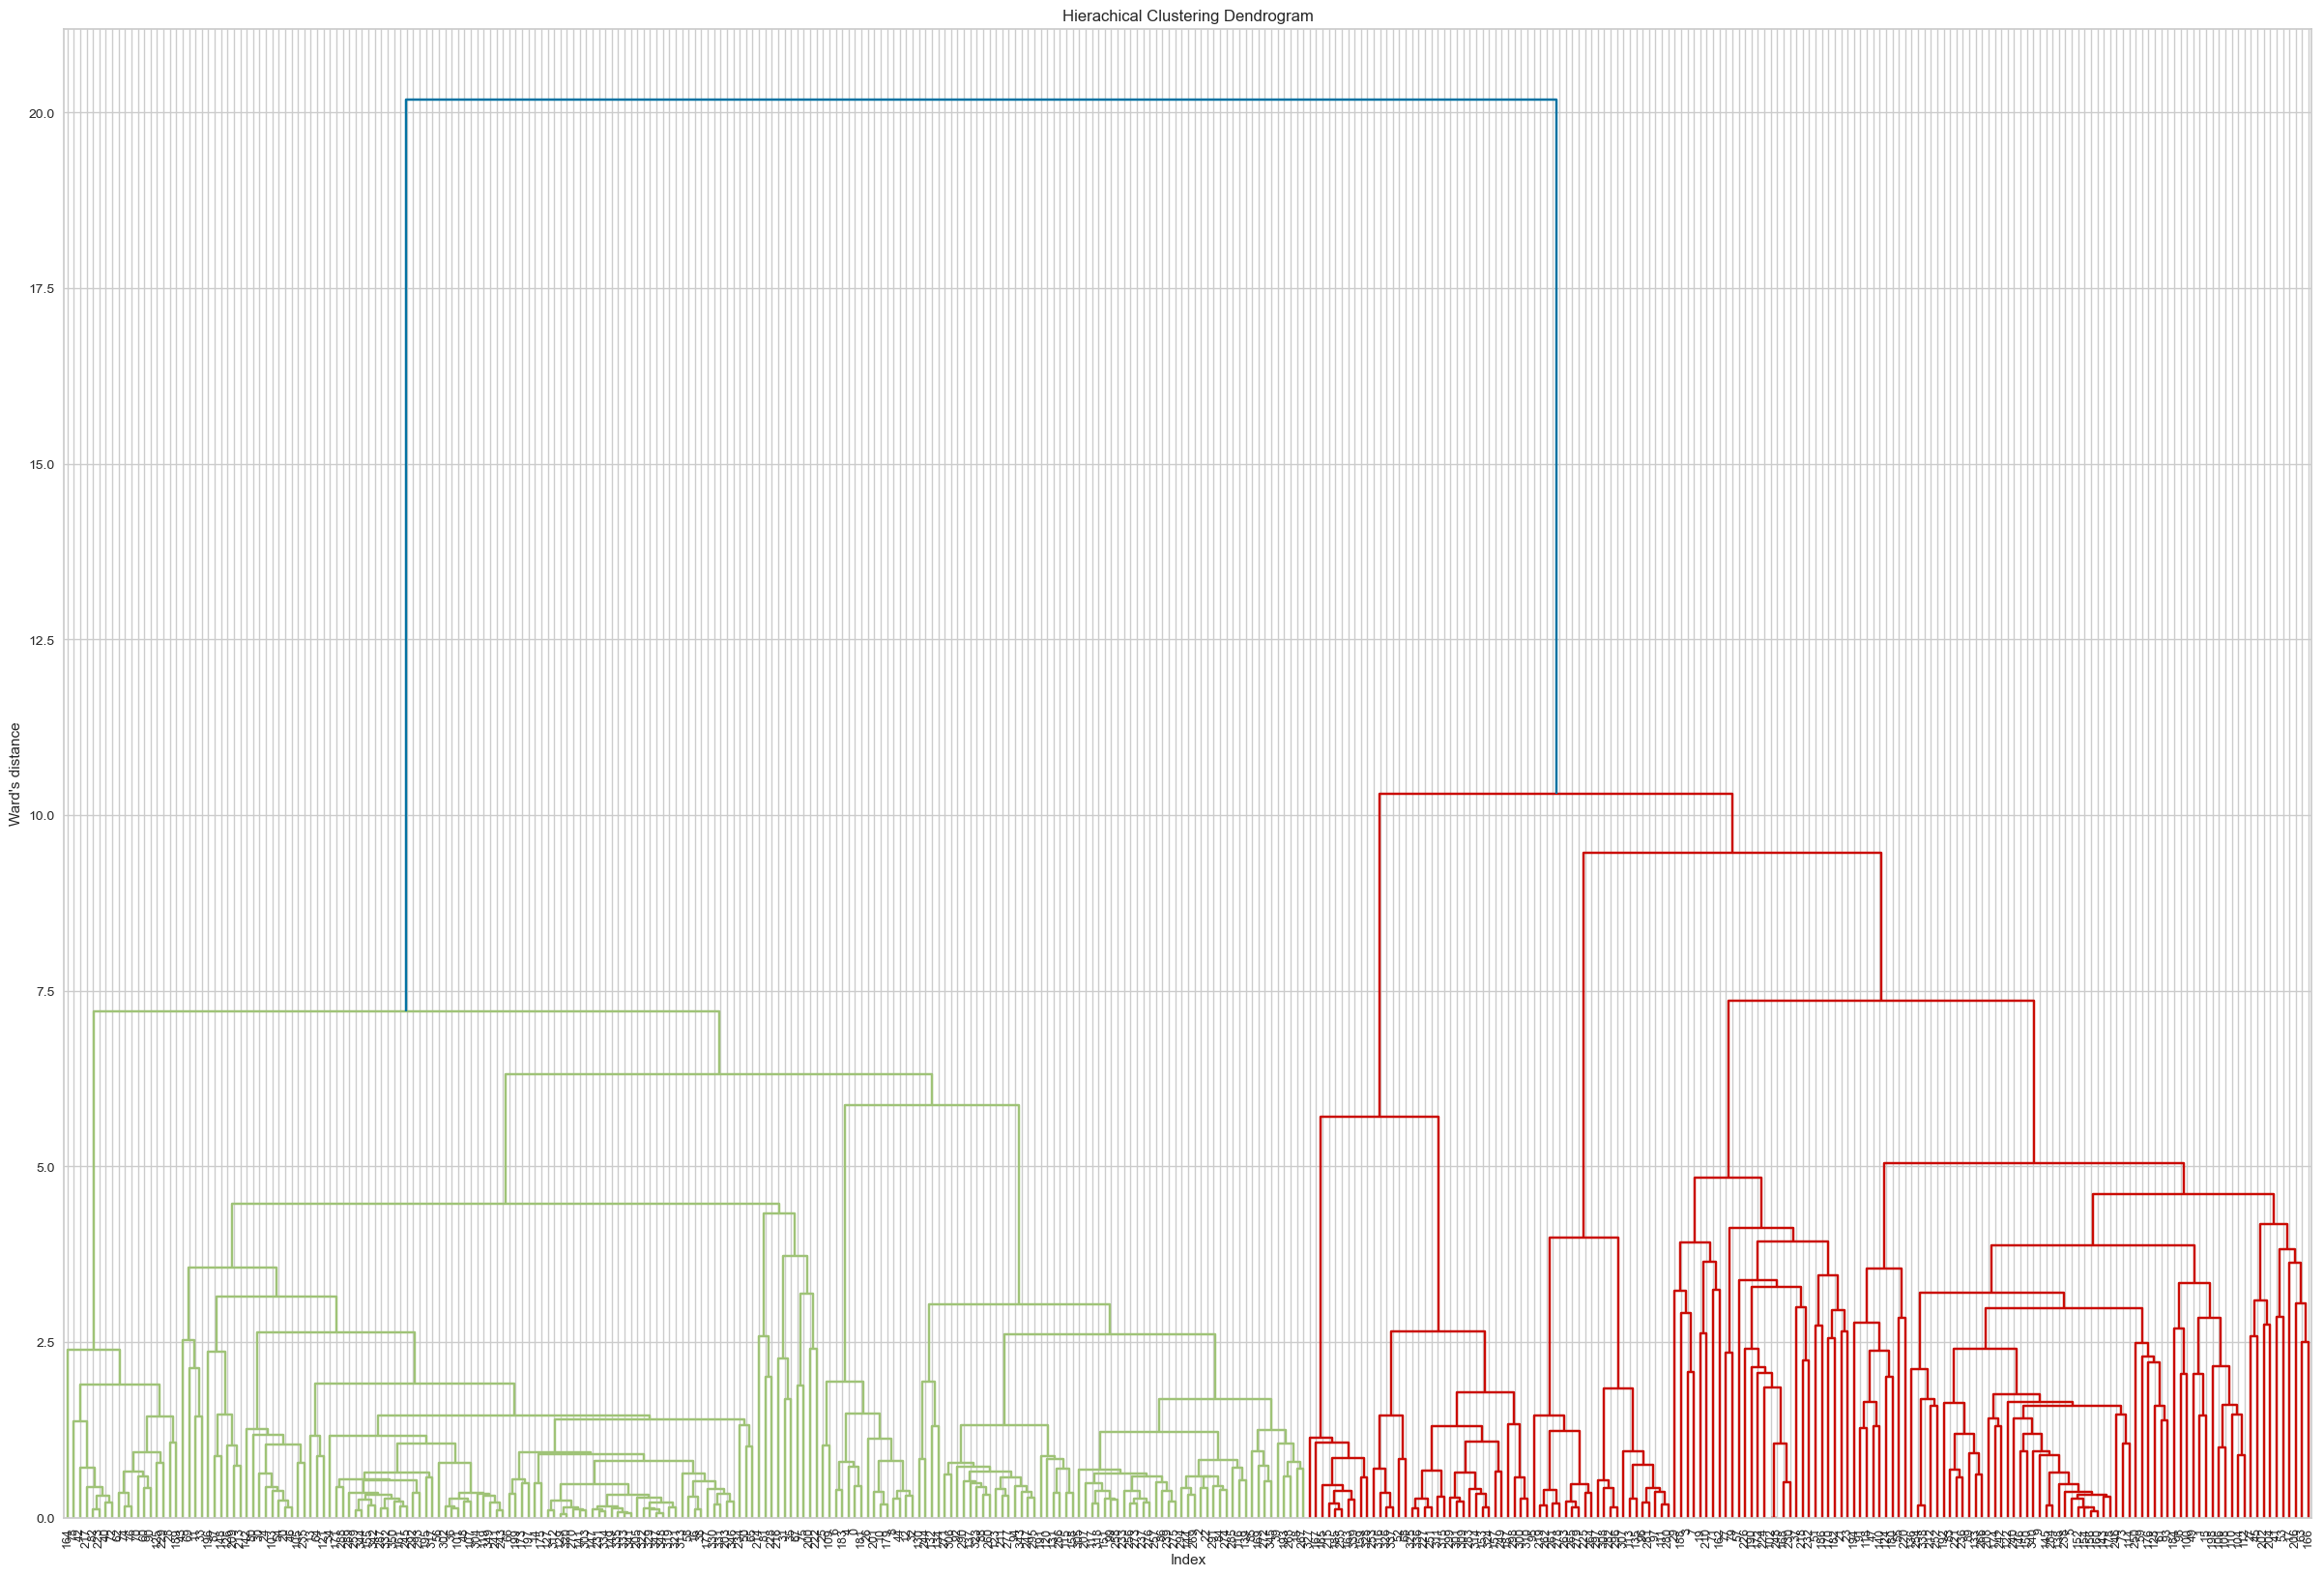

In [360]:
# Dendrogram - visualizing the linkage results 
plt.figure(figsize=(30,20))
plt.title("Hierachical Clustering Dendrogram")
plt.xlabel("Index")
plt.ylabel("Ward's distance")
dendrogram(distance,leaf_rotation=90.,leaf_font_size=9.,);

In [361]:
#Implementing the Naive Bayes model on the normalized data
model = GaussianNB()
model.fit(A_normalized, class_category);


In [362]:
#Implementing the Naive Bayes model on the first training data (70%)
gnb = GaussianNB()
gnb.fit(X_train, y_train)

GaussianNB()

In [363]:
#Predict the response for test dataset (first)
y_predict = gnb.predict(X_test)
y_predict

array([0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1,
       0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0], dtype=int64)

In [364]:
# Model Accuracy, checking how often is the classifier correct.
print("Accuracy:",metrics.accuracy_score(y_test, y_predict))

Accuracy: 0.9339622641509434


In [365]:
#Implementing the Naive Bayes model on the second training data (80%)
gnb2 = GaussianNB()
gnb2.fit(X2_train, y2_train)
#Predict the response for test dataset
y_predict2 = gnb.predict(X2_test)

#Implementing the Naive Bayes model on the third training data (90%)
gnb3 = GaussianNB()
gnb3.fit(X3_train, y3_train)
#Predict the response for test dataset
y_predict3 = gnb.predict(X3_test)

In [366]:
#prediction for the second test data
y_predict2

array([0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1,
       0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 1, 1, 0], dtype=int64)

In [367]:
# Model Accuracy, checking how often is the classifier correct.
print("Accuracy:",metrics.accuracy_score(y2_test, y_predict2))

Accuracy: 0.9436619718309859


In [368]:
#prediction for the third test data
y_predict3

array([0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0], dtype=int64)

In [369]:
# Model Accuracy, checking how often is the classifier correct.
print("Accuracy:",metrics.accuracy_score(y3_test, y_predict3))

Accuracy: 0.9166666666666666
